# GATE

We call 'GATE' a scenario where in observational study after fitting DML model we analyzing treatment effect heterogeneity between groups of clients

# Data

We will use DGP from Causalis. Read more at https://causalis.causalcraft.com/articles/generate_obs_hte_26_rich

In [18]:
from causalis.scenarios.unconfoundedness.dgp import generate_obs_hte_26_rich

data = generate_obs_hte_26_rich(return_causal_data=False, include_oracle=True)
data.head()

,user_id,y,d,tenure_months,avg_sessions_week,spend_last_month,age_years,income_monthly,prior_purchases_12m,support_tickets_90d,premium_user,mobile_user,urban_resident,referred_user,m,m_obs,tau_link,g0,g1,cate
0,1,0.000000,0.0,28.814654,1.0,77.936767,50.234101,1926.698301,1.0,2.0,1.0,1.0,1.0,0.0,0.045453,0.045453,0.089095,8.137981,9.142395,1.004414
1,2,80.099611,1.0,25.913345,3.0,53.777740,28.115859,5104.271509,3.0,0.0,1.0,1.0,0.0,1.0,0.041514,0.041514,0.246679,60.459257,78.817307,18.358049
2,3,6.400482,1.0,24.969929,10.0,134.764322,22.907062,5267.938255,8.0,3.0,0.0,1.0,1.0,0.0,0.052593,0.052593,0.162968,7.712855,9.138577,1.425723
3,4,2.788238,0.0,40.655089,5.0,59.517074,31.970490,6597.327018,3.0,2.0,1.0,1.0,1.0,0.0,0.036221,0.036221,0.188755,25.386510,31.159932,5.773422
4,5,0.000000,0.0,18.560899,3.0,74.370930,39.237248,4930.009628,5.0,1.0,1.0,1.0,0.0,0.0,0.036343,0.036343,0.174757,15.359250,18.600227,3.240977


In [19]:
print(f"Ground truth ATE is {data['cate'].mean()}")
print(f"Ground truth ATTE is {data[data['d'] == 1]['cate'].mean()}")

Ground truth ATE is 19.40958652966079
Ground truth ATTE is 10.914991423363862


In [20]:
from causalis.data_contracts import CausalData

causaldata = CausalData(df = data,
                        treatment='d',
                        user_id='user_id',
                        outcome='y',
                        confounders=['tenure_months',
                                     'avg_sessions_week',
                                     'spend_last_month',
                                     'age_years',
                                     'income_monthly',
                                     'prior_purchases_12m',
                                     'support_tickets_90d',
                                     'premium_user',
                                     'mobile_user',
                                     'urban_resident',
                                     'referred_user'])
causaldata

CausalData(df=(100000, 14), treatment='d', outcome='y', confounders=['tenure_months', 'avg_sessions_week', 'spend_last_month', 'age_years', 'income_monthly', 'prior_purchases_12m', 'support_tickets_90d', 'premium_user', 'mobile_user', 'urban_resident', 'referred_user'], user_id='user_id')

In [21]:
from causalis.shared import outcome_stats
outcome_stats(causaldata)

,treatment,count,mean,std,min,p10,p25,median,p75,p90,max
0,0,95051,76.087138,240.800713,0.0,0.0,0.0,8.39544,64.859278,190.227900,21396.007575
1,1,4949,58.506172,199.485625,0.0,0.0,0.0,0.00000,36.958280,148.837193,5143.642132


Our data has strong treatment class disbalance. Only 5% of sample activated in treatment.

Treatment group has lower mean LTV. It's too early to draw conclusions.

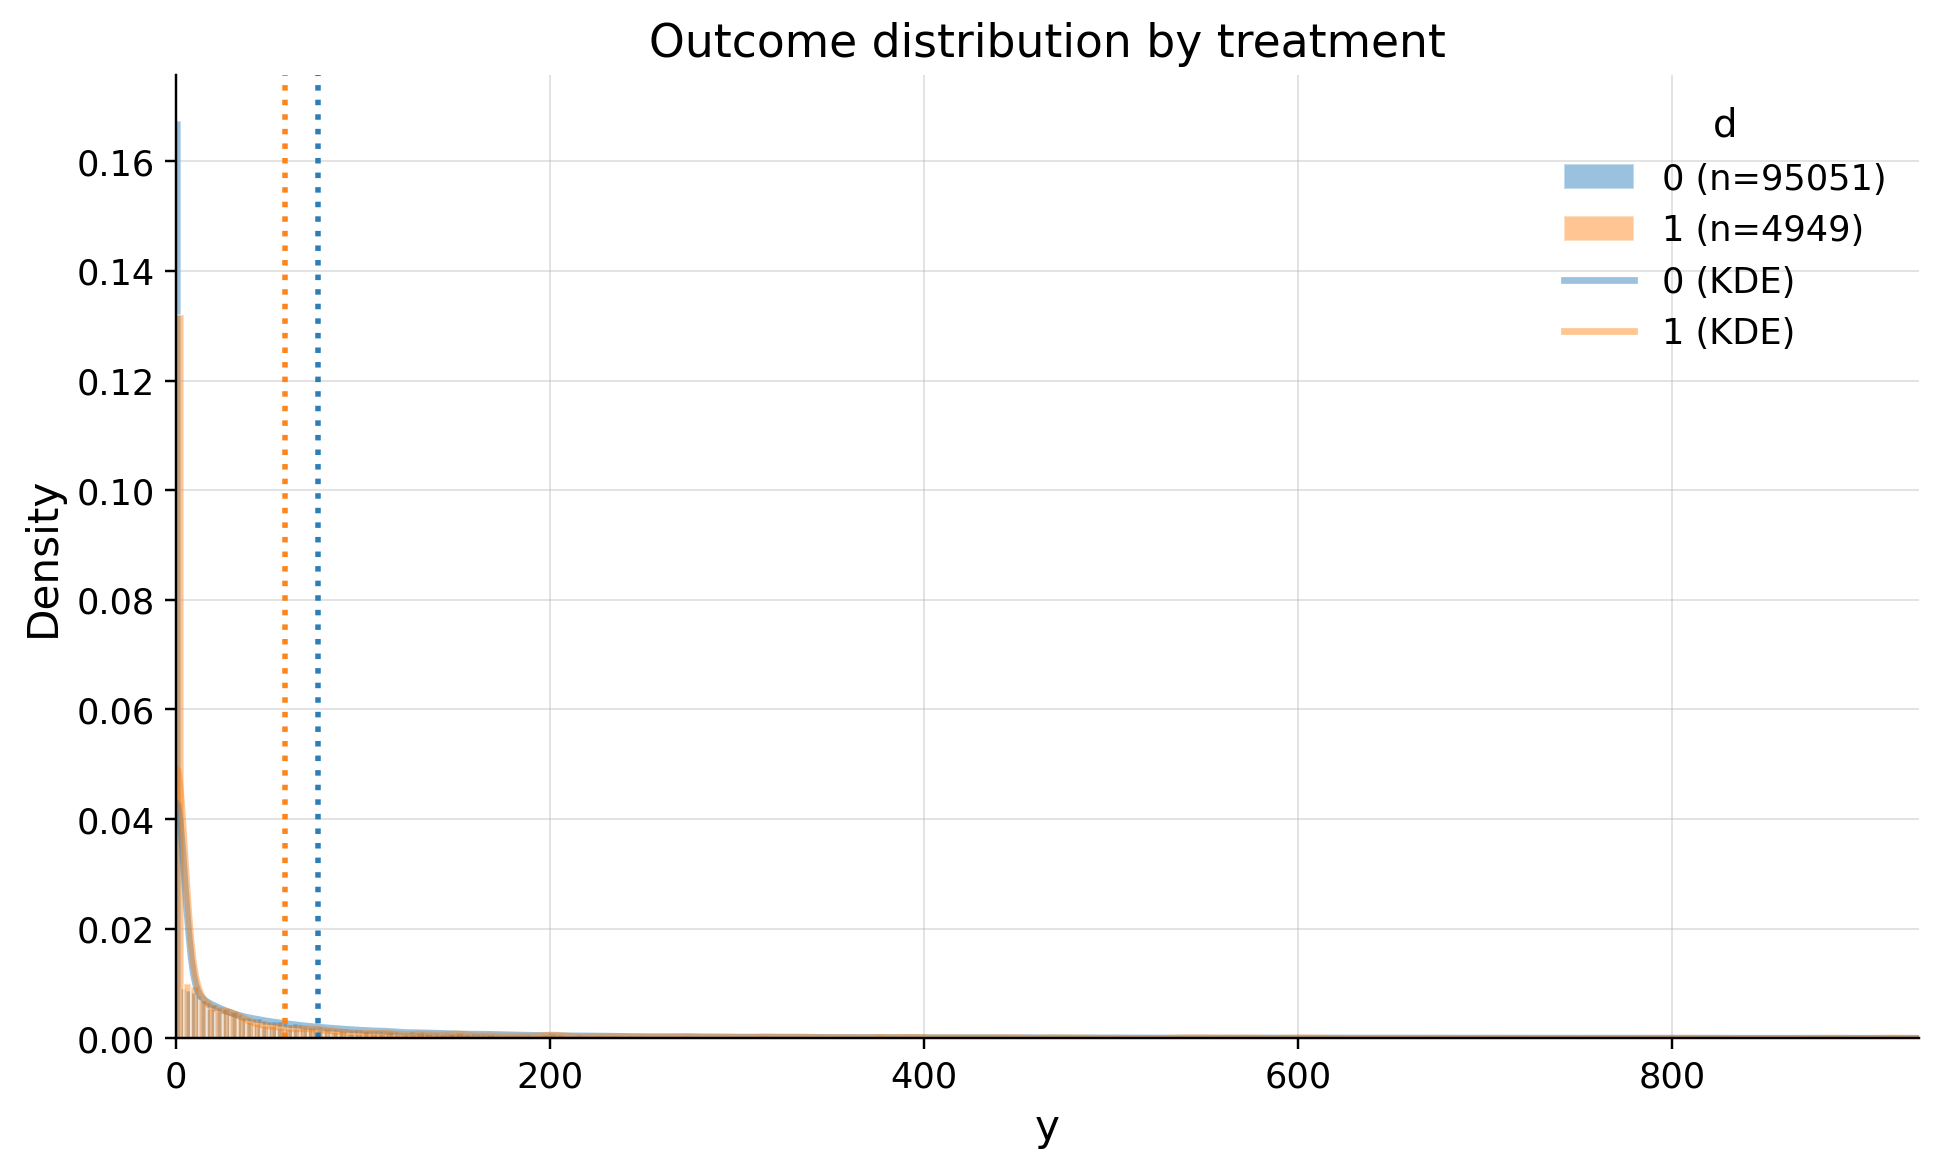

In [22]:
from causalis.shared.outcome_plots import outcome_plot_dist
outcome_plot_dist(causaldata)

We see large right tale

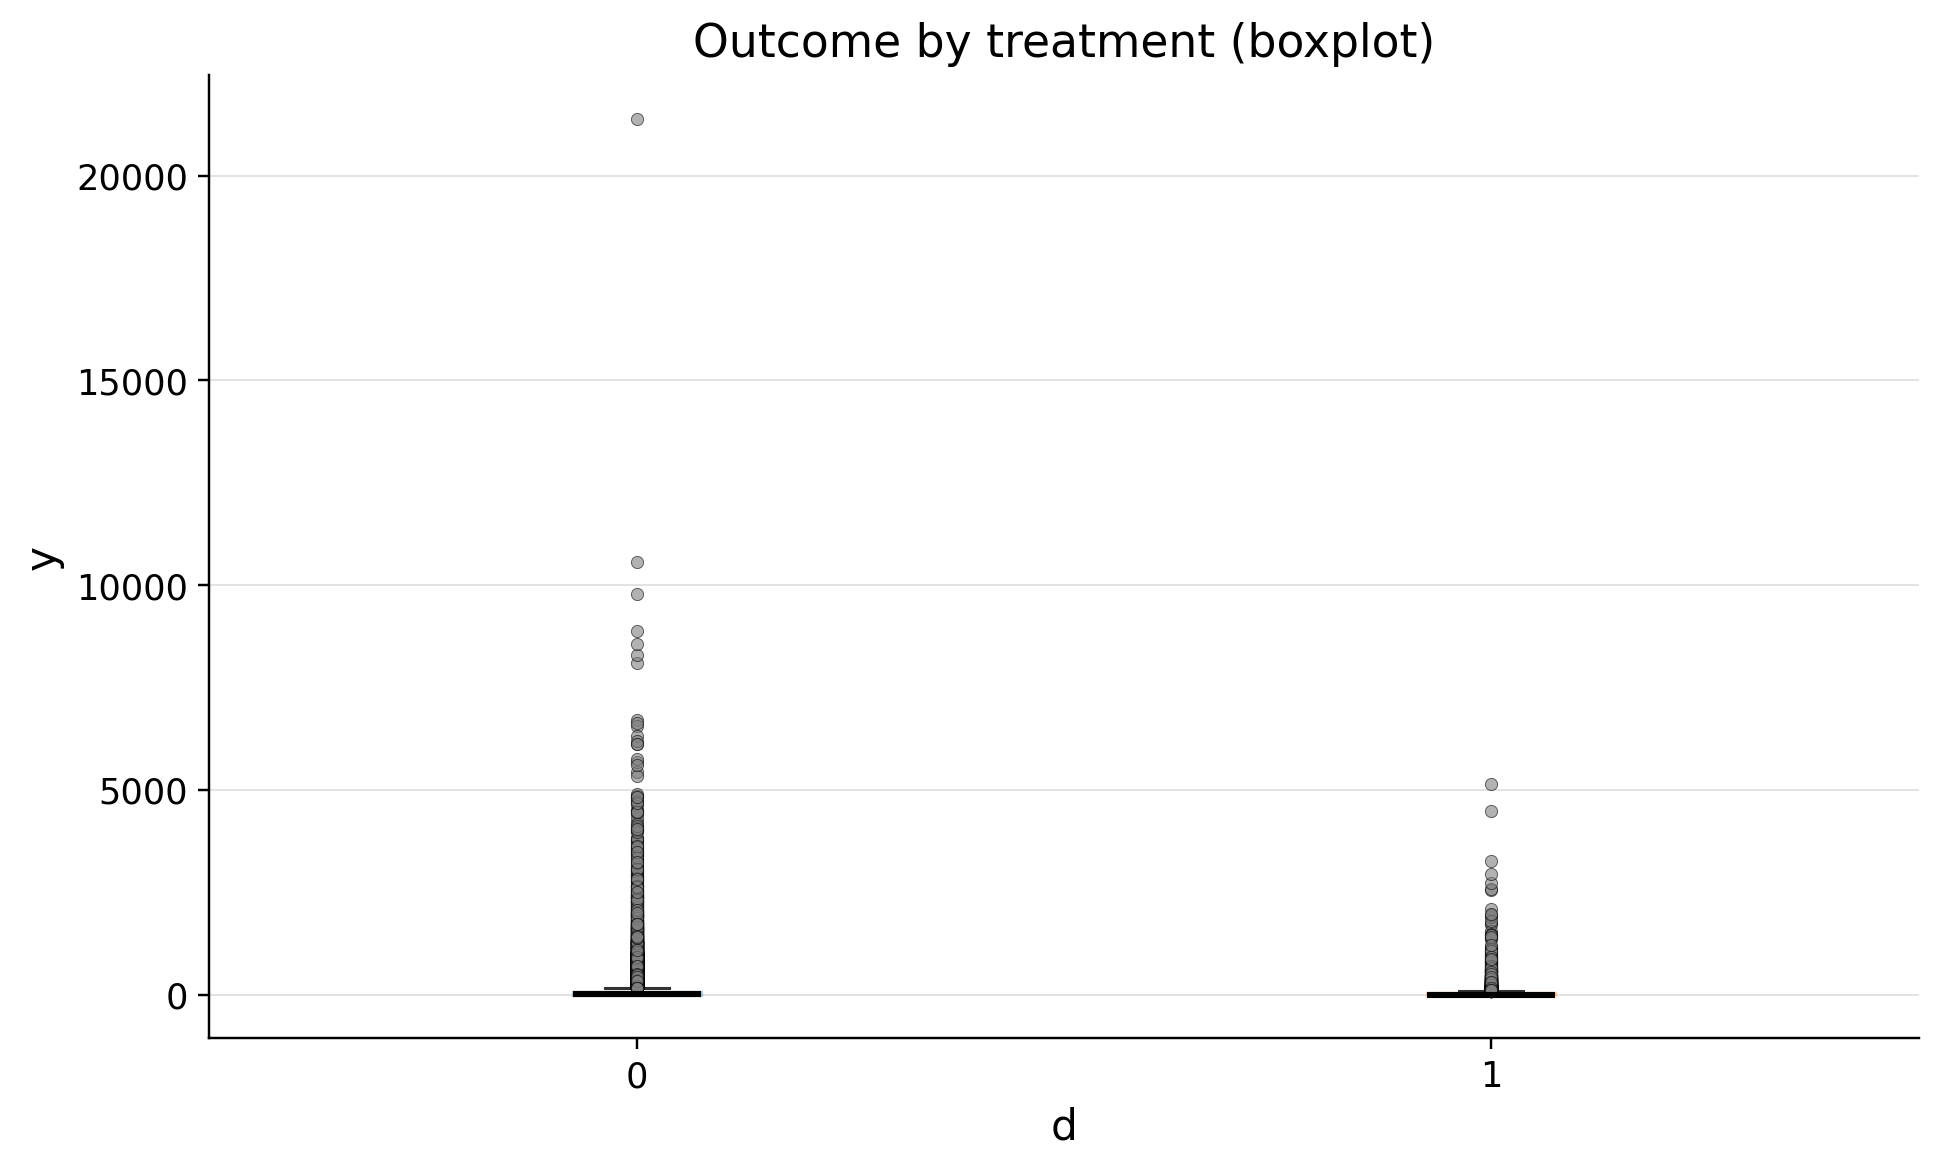

In [23]:
from causalis.shared.outcome_plots import outcome_plot_boxplot
outcome_plot_boxplot(causaldata)

In [24]:
from causalis.shared import outcome_outliers

outcome_outliers(causaldata)

,treatment,n,outlier_count,outlier_rate,lower_bound,upper_bound,has_outliers,method,tail
0,0,95051,11300,0.118884,-97.288916,162.148194,True,iqr,both
1,1,4949,721,0.145686,-55.437420,92.395699,True,iqr,both


We see many outliers. It's common situation for LTV metric. Dropping them will lead to a biased conclusion

In [25]:
from causalis.shared import confounders_balance

confounders_balance(causaldata)

,confounders,mean_d_0,mean_d_1,abs_diff,smd,ks_pvalue
0,premium_user,0.751807,0.591837,0.159970,-0.345721,0.00000
1,income_monthly,4549.385190,3918.058798,631.326392,-0.277611,0.00000
2,spend_last_month,89.091801,67.375389,21.716412,-0.268360,0.00000
3,support_tickets_90d,0.984545,1.259244,0.274699,0.253974,0.00000
4,avg_sessions_week,5.047753,4.230148,0.817606,-0.201735,0.00000
5,prior_purchases_12m,3.904220,3.513639,0.390581,-0.189372,0.00000
6,tenure_months,28.740100,25.559161,3.180939,-0.184156,0.00000
7,age_years,36.435984,34.809083,1.626901,-0.144142,0.00000
8,referred_user,0.271486,0.307133,0.035647,0.078671,0.00001
9,urban_resident,0.600793,0.568802,0.031991,-0.064954,0.00013


As we see clients are differ on this confounders. We need to controll them to make causal inference

# ATTE

ATTE is right estimand here. We will estimate effect on clients that were treated, had first purchase in our product

In [26]:
from causalis.scenarios.unconfoundedness import IRM

model = IRM(n_jobs=-1).fit(causaldata)

In [27]:
dml_result = model.estimate(score='ATTE')
dml_result.summary()

,value
field,
outcome,y
estimand,ATTE
model,IRM
value,"10.7928 (ci_abs: 5.6642, 15.9214)"
value_relative,"22.6201 (ci_rel: 11.1447, 34.0955)"
alpha,0.0500
p_value,0.0000
is_significant,True
n_treated,4949


Our estimate is 12.1542 dollars (ci_abs: 7.7933, 16.5152). Mean in treatment group is 58.5062 dollars, so without our product it would be 46.3520 dollars.

## GATET

## Quantile groups GATET

In [28]:
import pandas as pd

groups = pd.qcut(data["prior_purchases_12m"], q=5, duplicates="drop")
result = model.estimate(score="GATET", groups=groups)

result.summary()

,group,value,is_significant,ci_lower,ci_upper,n_group,n_treated,n_control,share_treated,std_error,test_stat,p_value,mean_phi,std_phi,mean_propensity,min_propensity,max_propensity
0,"prior_purchases_12m=(-0.001, 2.0]",4.891322,False,-0.495344,10.277988,27484,1700,25784,0.06185,2.748349,1.779731,0.07512,4.891322,455.755006,0.059950,0.01,0.729134
1,"prior_purchases_12m=(2.0, 3.0]",5.018750,False,-10.677923,20.715422,19182,984,18198,0.05130,8.008653,0.626666,0.53088,5.018750,1109.725795,0.050400,0.01,0.781507
2,"prior_purchases_12m=(3.0, 4.0]",3.662981,False,-5.784082,13.110044,18236,847,17389,0.04645,4.820019,0.759952,0.44728,3.662981,650.380074,0.046072,0.01,0.668782
3,"prior_purchases_12m=(4.0, 6.0]",20.971652,True,9.745755,32.197549,23812,1014,22798,0.04258,5.727604,3.661505,0.00025,20.971652,888.707081,0.041555,0.01,0.645209
4,"prior_purchases_12m=(6.0, 16.0]",39.089381,True,11.122518,67.056244,11286,404,10882,0.03580,14.269070,2.739448,0.00615,39.089381,1524.593896,0.033884,0.01,0.446225


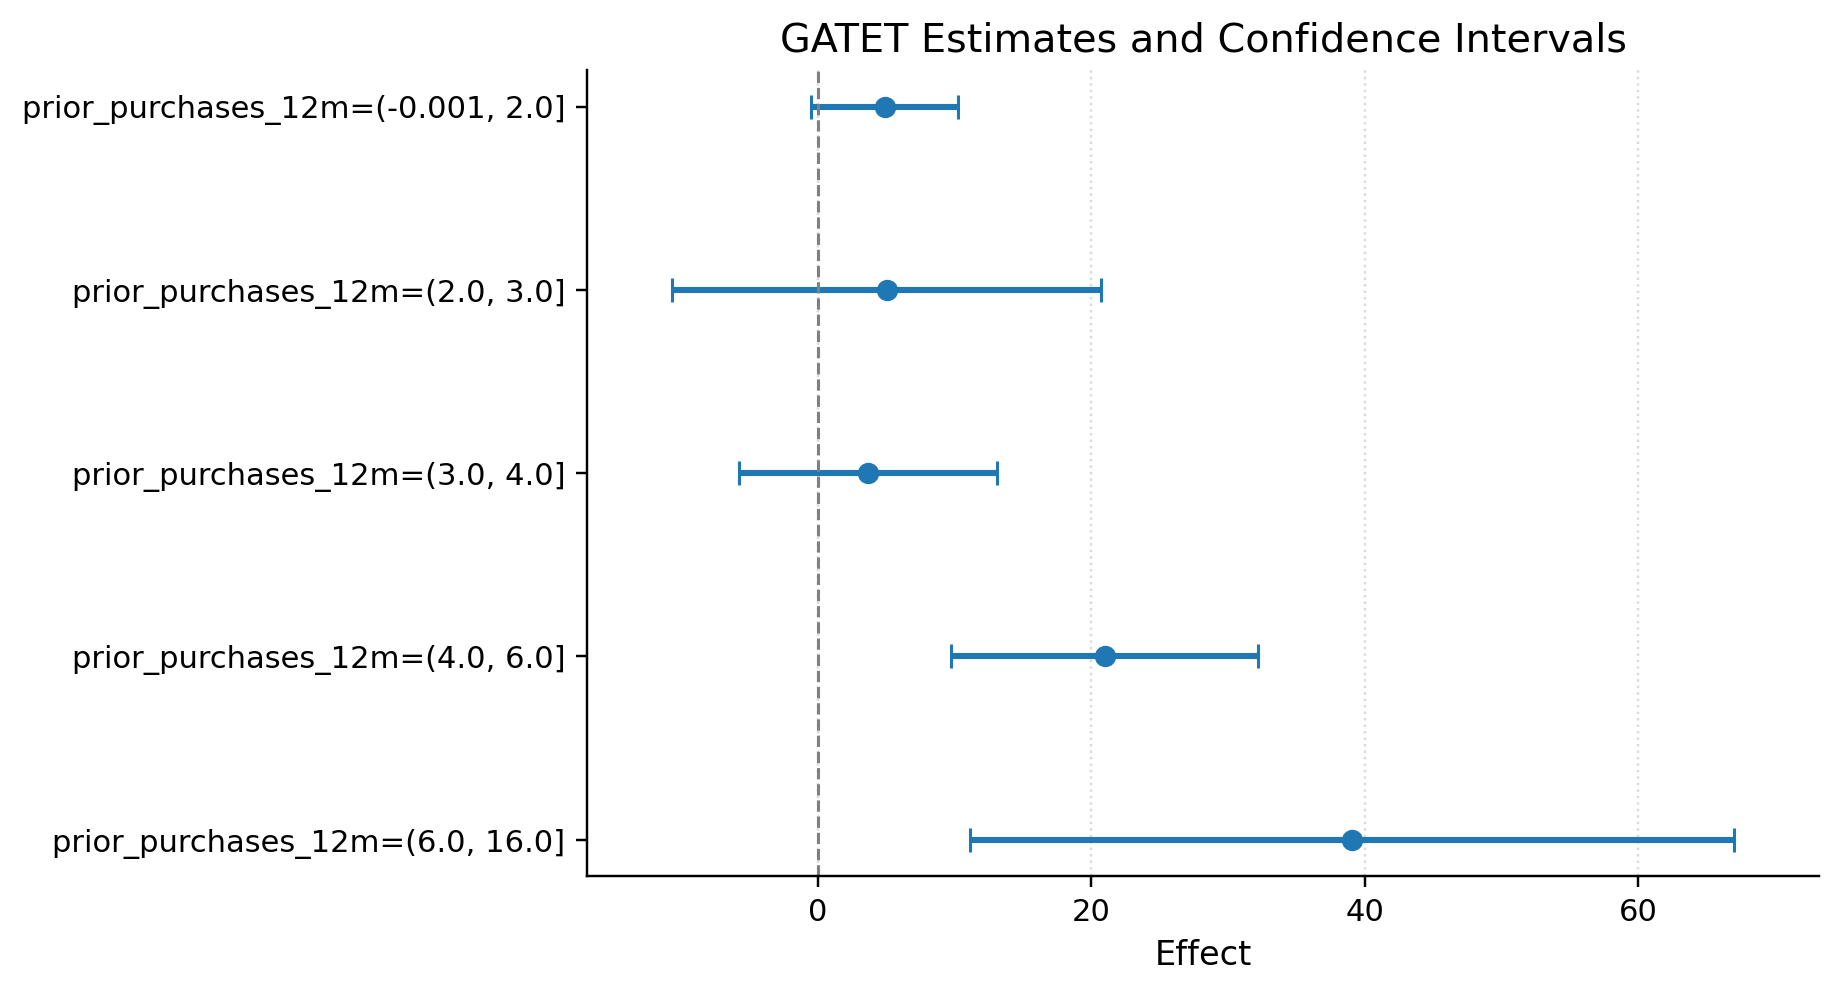

In [29]:
from causalis.scenarios.gate import gate_plot

gate_plot(result)

## Integer groups GATET

In [30]:
result = model.estimate(score='GATET', groups=data['mobile_user'])
result.summary()

,group,value,is_significant,ci_lower,ci_upper,n_group,n_treated,n_control,share_treated,std_error,test_stat,p_value,mean_phi,std_phi,mean_propensity,min_propensity,max_propensity
0,mobile_user=0.0,4.680226,False,-2.135325,11.495777,12565,643,11922,0.05117,3.477386,1.345904,0.17833,4.680226,389.460892,0.048397,0.01,0.413849
1,mobile_user=1.0,11.705579,True,5.899401,17.511757,87435,4306,83129,0.04925,2.962390,3.951397,0.00008,11.705579,877.745103,0.048246,0.01,0.781507


## Formal group comparisons

- `result.summary()` answers which subgroup effects are different from `0`.
- `result.contrast(...)` answers whether one subgroup effect differs from another.
- `result.pairwise_summary(reference=...)` compares every subgroup against a chosen reference group.

In [31]:
result.contrast("mobile_user=1.0", "mobile_user=0.0").summary()

,value
field,
estimand,GATET_CONTRAST
model,IRM
contrast,mobile_user=1.0 - mobile_user=0.0
left_group,mobile_user=1.0
right_group,mobile_user=0.0
value,"7.0254 (ci_abs: -1.9281, 15.9788)"
std_error,4.5681
test_stat,1.5379
alpha,0.0500


In [32]:
result.pairwise_summary(reference="mobile_user=0.0")

,left_group,right_group,contrast_label,left_value,right_value,estimate_diff,std_error,test_stat,p_value,p_value_adj,ci_lower,ci_upper,is_significant,is_significant_adj,n_left,n_right,alpha,p_adjust
0,mobile_user=1.0,mobile_user=0.0,mobile_user=1.0 - mobile_user=0.0,11.705579,4.680226,7.025353,4.568147,1.5379,0.124073,0.124073,-1.928051,15.978756,False,False,87435,12565,0.05,none


## Manual groups GATET

In [33]:
import numpy as np

manual_groups = pd.Series(np.where(causaldata.df["age_years"] < 30, "Young", 
                                   np.where(causaldata.df["age_years"] < 50, "Middle", "Senior")),
                          index=causaldata.df.index)

model.estimate(score="GATET", groups=manual_groups).summary()

,group,value,is_significant,ci_lower,ci_upper,n_group,n_treated,n_control,share_treated,std_error,test_stat,p_value,mean_phi,std_phi,mean_propensity,min_propensity,max_propensity
0,0=Middle,9.615972,True,3.159233,16.072711,57050,2633,54417,0.04615,3.294315,2.918959,0.00351,9.615972,787.759483,0.045454,0.01,0.729134
1,0=Senior,-2.879664,False,-33.313919,27.554592,12133,504,11629,0.04154,15.527967,-0.185450,0.85288,-2.879664,1709.316947,0.039159,0.01,0.781507
2,0=Young,16.305796,True,10.249876,22.361717,30817,1812,29005,0.05880,3.089812,5.277277,0.00000,16.305796,546.201574,0.057055,0.01,0.587350


## Multi-column indicator groups GATET

Yes. `groups=` for `score="GATET"` can be a multi-column DataFrame of 0/1 subgroup indicators.

The columns must define a strict partition of the fitted sample:
- every column must be binary,
- every row must belong to exactly one subgroup,
- every subgroup must contain at least one treated observation.

Groups with no controls are still accepted for GATET, but the estimator emits a warning because within-group overlap is degenerate.


In [34]:
age_bucket = pd.cut(
    causaldata.df["age_years"],
    bins=[-np.inf, 30, 50, np.inf],
    labels=["Young", "Middle", "Senior"],
    right=False,
)

segment = age_bucket.astype(str) + "_mobile=" + causaldata.df["mobile_user"].astype(int).astype(str)

groups = pd.get_dummies(segment, dtype=int)
groups.index = causaldata.df["user_id"]

assert (groups.sum(axis=1) == 1).all()

model.estimate(score="GATET", groups=groups).summary()


,group,value,is_significant,ci_lower,ci_upper,n_group,n_treated,n_control,share_treated,std_error,test_stat,p_value,mean_phi,std_phi,mean_propensity,min_propensity,max_propensity
0,Middle_mobile=0,6.594227,False,-1.758940,14.947394,7511,362,7149,0.04820,4.261898,1.547251,0.12180,6.594227,369.422120,0.046393,0.01,0.397149
1,Middle_mobile=1,10.097642,True,2.730341,17.464943,49539,2271,47268,0.04584,3.758896,2.686332,0.00722,10.097642,837.543417,0.045312,0.01,0.729134
2,Senior_mobile=0,-5.447845,False,-30.887664,19.991975,2500,113,2387,0.04520,12.979738,-0.419719,0.67469,-5.447845,645.393062,0.040688,0.01,0.389281
3,Senior_mobile=1,-2.137453,False,-40.681311,36.406405,9633,391,9242,0.04059,19.665595,-0.108690,0.91345,-2.137453,1928.826654,0.038762,0.01,0.781507
4,Young_mobile=0,7.368343,False,-0.708975,15.445661,2554,168,2386,0.06578,4.121156,1.787931,0.07379,7.368343,208.986937,0.061838,0.01,0.413849
5,Young_mobile=1,17.219113,True,10.596546,23.841679,28263,1644,26619,0.05817,3.378922,5.096037,0.00000,17.219113,572.134564,0.056623,0.01,0.587350
